In [68]:
import numpy as np
import matplotlib.pyplot as plt
from numcompute_stream.io import iter_chunks
from numcompute_stream.pipeline import Pipeline
from numcompute_stream.preprocessing import Imputer, StandardScaler
from numcompute_stream.tree import DecisionTreeClassifier
from numcompute_stream.metrics import F1, StreamingAUC, Accuracy
from numcompute_stream.stream import StreamTrainer
from numcompute_stream.visualise import plot_metric_over_time, compare_models, plot_predictions_vs_ground_truth

In [69]:
rng = np.random.default_rng(0)
n = 12000
X = rng.uniform(-1, 1, size=(n, 4))
y = np.where(X[:, 0] ** 2 + X[:, 1] ** 2 < 0.5, "in", "out")            # circle
y[n // 2:] = np.where(X[n // 2:, 0] + X[n // 2:, 2] > 0, "in", "out")   # drift: new rule
flip = rng.random(n) < 0.05
y[flip] = np.where(y[flip] == "in", "out", "in")                        # label noise
X[rng.random(X.shape) < 0.03] = np.nan                                  # missing values


In [70]:
def run(buffer_size):
    pipe = Pipeline([("impute", Imputer()), ("scale", StandardScaler()),
                     ("tree", DecisionTreeClassifier(max_depth=6, buffer_size=buffer_size))])
    trainer = StreamTrainer(pipe, metrics={"auc": StreamingAUC(pos_label="in"),
                                           "f1": F1(pos_label="in"),
                                           "rolling_accuracy": Accuracy(window=10)})
    for X_chunk, y_chunk in iter_chunks(X, y, chunk_size=100):
        trainer.score_chunk(X_chunk, y_chunk)   # test on unseen data first...
        trainer.fit_chunk(X_chunk, y_chunk)     # ...then train on it
    return trainer

small, large = run(300), run(2000)


<Axes: title={'center': 'Per-chunk accuracy (buffer 300)'}, xlabel='Chunk', ylabel='Accuracy'>

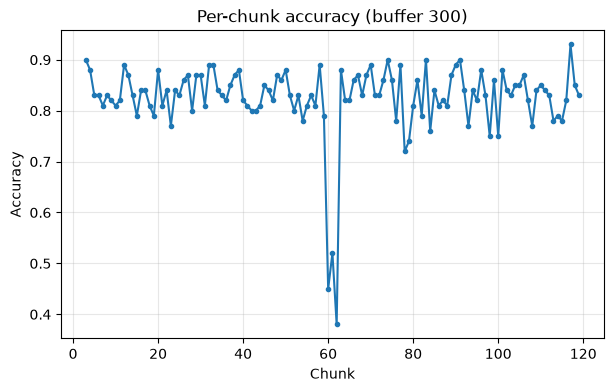

In [71]:
plot_metric_over_time(small.history("accuracy"), "Per-chunk accuracy (buffer 300)", "Accuracy")


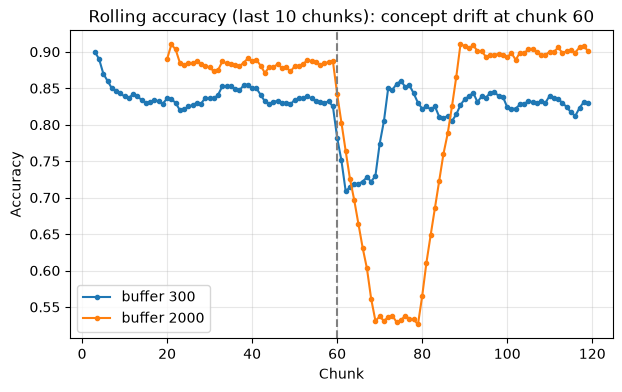

In [72]:
ax = compare_models(small.history("rolling_accuracy"), large.history("rolling_accuracy"),
                    labels=("buffer 300", "buffer 2000"),
                    title="Rolling accuracy (last 10 chunks): concept drift at chunk 60",
                    ylabel="Accuracy")
ax.axvline(60, color="grey", linestyle="--")

<Axes: title={'center': 'Time per fit_chunk (spikes = retrains)'}, xlabel='Samples seen', ylabel='ms'>

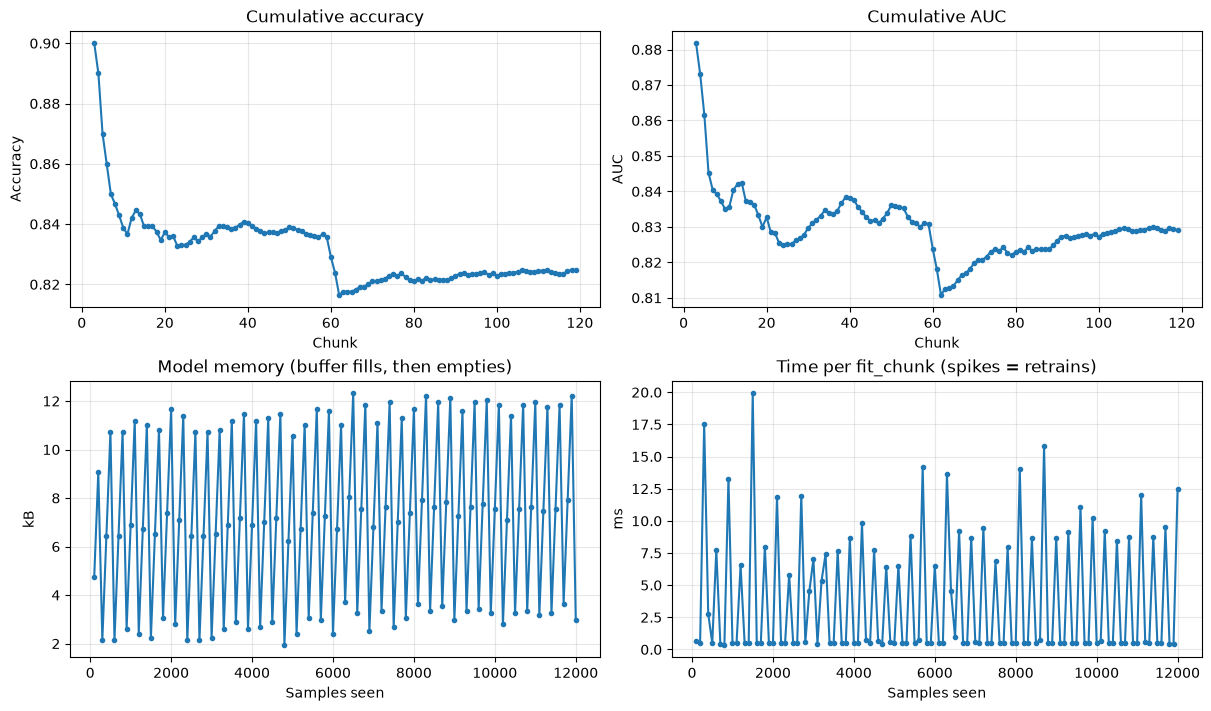

In [73]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
plot_metric_over_time(small.history("cumulative_accuracy"), "Cumulative accuracy", "Accuracy", ax=axes[0, 0])
plot_metric_over_time(small.history("auc"), "Cumulative AUC", "AUC", ax=axes[0, 1])
plot_metric_over_time(small.history("model_bytes") / 1024, "Model memory (buffer fills, then empties)", "kB",
                      x=small.history("n_samples_seen"), xlabel="Samples seen", ax=axes[1, 0])
plot_metric_over_time(small.history("fit_time") * 1000, "Time per fit_chunk (spikes = retrains)", "ms",
                      x=small.history("n_samples_seen"), xlabel="Samples seen", ax=axes[1, 1])

<Axes: title={'center': 'Predictions vs ground truth\naccuracy 0.840 on 50 samples'}, xlabel='Sample', ylabel='Label'>

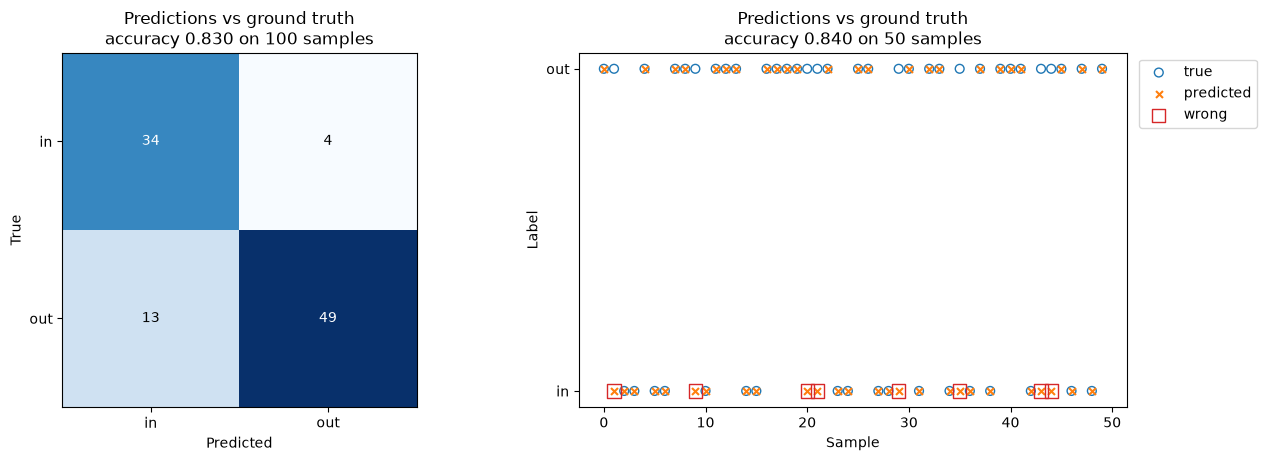

In [74]:
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
plot_predictions_vs_ground_truth(small.last_y_true_, small.last_y_pred_, ax=left)
plot_predictions_vs_ground_truth(small.last_y_true_[:50], small.last_y_pred_[:50], kind="samples", ax=right)
